In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [2]:
#df = pd.read_csv('RatioIntzones_merged.csv')
df = pd.read_csv('DREADDs_SFC_Intzones_merged_v3.csv')


df = df.drop('Cups Hab', 1)

In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
print(newdf)

   Experimental Condition  Left preference control
0                Cups LTM         0.115385       y
1                Cups LTM         0.041064       y
2                Cups LTM        -0.165333       y
3                Cups LTM        -0.082667       n
4                Cups LTM         0.087719       y
..                    ...              ...     ...
79                    LTM         0.300000       n
80                    LTM         0.869919       n
81                    LTM         0.200000       n
82                    LTM         0.425561       n
83                    LTM         0.578186       n

[84 rows x 3 columns]


In [4]:
#df_h = pd.read_csv('RatioHalves_merged.csv')
df_h = pd.read_csv('DREADDs_merged_SFC_v3.csv')


df_h = df_h.drop('Cups Hab', 1)
print(df_h.loc[df_h['Control']=='y',:])

    Group  Cups LTM       LTM Control
0       1  0.138000  0.032667       y
1       2 -0.174000 -0.180000       y
3       4  0.182047  0.609333       y
4       5  0.083333  0.410000       y
5       6  0.024400  0.057667       y
7       8  0.071067 -0.104000       y
8       9 -0.134667 -0.081227       y
9      10 -0.071067  0.012000       y
10     11  0.061204  0.340000       y
11     12 -0.031333  0.041333       y
12     13 -0.039267  0.122733       y
13     14  0.009333 -0.183867       y
27     28 -0.018667  0.053333       y
28     29 -0.234667 -0.122667       y
29     30  0.110667  0.194000       y
30     31 -0.334667 -0.081227       y
31     32 -0.081067  0.100000       y
32     33  0.104000 -0.240000       y
33     34 -0.011333  0.413333       y
34     35 -0.392667  0.227333       y
36     37  0.333061 -0.183140       y
37     38 -0.068991  0.329480       y


In [5]:
data = []

for el in df_h.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df_h[el]):
        data.append([el,val,df_h.iloc[i].get('Control')])
        
newdf_h = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
# print(newdf)
newdf_h = newdf_h.replace({'Cups LTM': "Cups LTM halves", "LTM": "LTM halves"})

newdf = pd.concat([newdf_h,newdf])
newdf

,Experimental Condition,Left preference,control
0,Cups LTM halves,0.138000,y
1,Cups LTM halves,-0.174000,y
2,Cups LTM halves,-0.052000,n
3,Cups LTM halves,0.182047,y
4,Cups LTM halves,0.083333,y
...,...,...,...
79,LTM,0.300000,n
80,LTM,0.869919,n
81,LTM,0.200000,n
82,LTM,0.425561,n


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript back

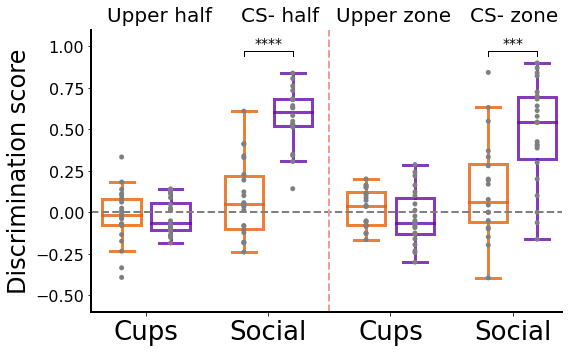

In [8]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


text_boxplot = ['','***','****']
colors = ["C7","C7"]
colors_boxplot = ['#e66007', "#680aab"]

ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors,
    jitter=0,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=3,
    **PROPS
)

plt.axhline(linewidth=2, color='grey',ls='--')
plt.axvline(linewidth=2, x=1.5, color='#f29a94',ls='--')


data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)
plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social','Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

ax.text(-0.32,1.15,'Upper half', fontsize = 20)
ax.text(0.78,1.15,'CS- half', fontsize = 20)

ax.text(1.55,1.15,'Upper zone', fontsize = 20)
ax.text(2.65,1.15,'CS- zone', fontsize = 20)

ax.set_xlabel("",fontsize=20)
#ax.set_ylabel('Discrimination score \n $(t_{1}-t_{2})/(t_{total})$', fontsize = 24)
ax.set_ylabel('Discrimination score', fontsize = 24)


ax.set_ylim([-0.5999,1.1])
ax.set_xlim([-0.45,3.4])

#significance(ax,0,data_ratio,newdf.loc[newdf['Experimental Condition']=='Cups LTM']['Left preference'].max(),text=text_boxplot[0])
significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[2])
significance(ax,3,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1])

#plt.title("Side preference arena", fontsize=24,y=1.1)

fig = ax.get_figure()

adjust_box_widths(fig, 0.8)
fig.set_size_inches(8,5)
ax.tick_params(axis='y', which='major', labelsize=16)

plt.tight_layout()
fig.tight_layout()
fig.savefig("RatioIntzones_Halves_merged_DREADDs.jpg",dpi=500,bbox_inches='tight')
plt.savefig('RatioIntzones_Halves_merged_DREADDs.eps', format='eps')

